# CPU vs GPU Performance Benchmark
Compares 5000 x 5000 matrix multiplication on CPU (NumPy) vs GPU (PyTorch + CUDA).

**Before running:** Runtime > Change runtime type > T4 GPU

In [1]:
import time, numpy as np, torch
import matplotlib.pyplot as plt

print("GPU available:", torch.cuda.is_available())
print("GPU name:", torch.cuda.get_device_name(0))

GPU available: True
GPU name: Tesla T4


## Matrix multiplication (5000 x 5000)

In [2]:
N = 5000

# CPU (NumPy)
a = np.random.rand(N, N).astype(np.float32)
b = np.random.rand(N, N).astype(np.float32)
t = time.time()
np.matmul(a, b)
cpu_mat = time.time() - t

# GPU (PyTorch + CUDA)
ag = torch.rand(N, N, device="cuda")
bg = torch.rand(N, N, device="cuda")
torch.matmul(ag, bg); torch.cuda.synchronize()
t = time.time()
torch.matmul(ag, bg)
torch.cuda.synchronize()                          # waiting for GPU to finish
gpu_mat = time.time() - t

print(f"CPU: {cpu_mat:.3f}s | GPU: {gpu_mat:.4f}s | Speedup: {cpu_mat/gpu_mat:.1f}x")

CPU: 2.333s | GPU: 0.0623s | Speedup: 37.4x


## Results

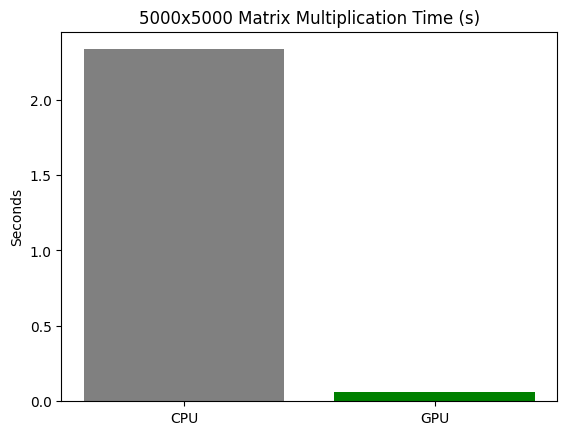

In [3]:
plt.bar(["CPU", "GPU"], [cpu_mat, gpu_mat], color=["gray", "green"])
plt.title("5000x5000 Matrix Multiplication Time (s)")
plt.ylabel("Seconds")
plt.savefig("results.png"); plt.show()

## Conclusion
The GPU was **37.4 times faster** than the CPU for 5000 x 5000 matrix multiplication . Each output cell can be computed independently, so the GPU's thousands of cores work in parallel. Neural networks are mostly matrix multiplications, which is why GPUs matter for AI.

**Notes:**
- A warm-up run and `torch.cuda.synchronize()` were used for fair timing, since GPU calls are asynchronous.